<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Rows: 569  Features: 30  Classes: [np.str_('benign'), np.str_('malignant')] 

Train size: 455  Test size: 114 

benign     prior = 0.637
malignant  prior = 0.363

Confusion Matrix (rows = actual, columns = predicted):
           benign  malignant
benign         65          2
malignant       6         41

Accuracy: 92.98%

Class        Precision  Recall
benign       0.92       0.97
malignant    0.95       0.87


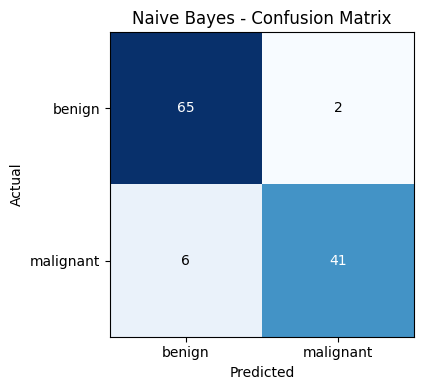

In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer

# ---- 1. Load Dataset from scikit-learn ----
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
# Map target integers back to string class names ('malignant', 'benign')
df['diagnosis'] = [cancer.target_names[t] for t in cancer.target]

X = df.iloc[:, :-1].values.astype(float)
y = df['diagnosis'].values
classes = sorted(set(y))
print("Rows:", len(df), " Features:", X.shape[1], " Classes:", classes, "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))
Xtr, Xte = X[idx[:split]], X[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(Xtr), " Test size:", len(Xte), "\n")

# ---- 3. Training: learn prior, mean and variance of each class ----
prior, mean, var = {}, {}, {}
for c in classes:
    Xc = Xtr[ytr == c]
    prior[c] = len(Xc) / len(Xtr)          # P(class)
    mean[c] = Xc.mean(axis=0)              # mean of each feature
    var[c] = Xc.var(axis=0) + 1e-9         # variance of each feature
    print(f"{c:<10} prior = {prior[c]:.3f}")

# ---- 4. Gaussian probability ----
def gaussian(x, m, v):
    return np.exp(-((x - m) ** 2) / (2 * v)) / np.sqrt(2 * np.pi * v)

# ---- 5. Prediction: P(class) x P(x1|class) x P(x2|class) ... ----
def predict(x):
    scores = {}
    for c in classes:
        # Add a tiny epsilon 1e-15 inside log to avoid log(0) warnings
        scores[c] = np.log(prior[c]) + np.sum(np.log(gaussian(x, mean[c], var[c]) + 1e-15))
    return max(scores, key=scores.get)

preds = np.array([predict(x) for x in Xte])

# ---- 6. Confusion matrix ----
n = len(classes)
cm = np.zeros((n, n), dtype=int)
for a, p in zip(yte, preds):
    cm[classes.index(a), classes.index(p)] += 1

print("\nConfusion Matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(cm, index=classes, columns=classes))

# ---- 7. Accuracy ----
accuracy = np.trace(cm) / cm.sum() * 100
print(f"\nAccuracy: {accuracy:.2f}%")

# ---- 8. Per-class precision and recall ----
print("\nClass        Precision  Recall")
for i, c in enumerate(classes):
    precision = cm[i, i] / cm[:, i].sum() if cm[:, i].sum() else 0
    recall = cm[i, i] / cm[i, :].sum() if cm[i, :].sum() else 0
    print(f"{c:<12} {precision:.2f}       {recall:.2f}")

# ---- 9. Plot confusion matrix ----
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(n)); ax.set_xticklabels(classes)
ax.set_yticks(range(n)); ax.set_yticklabels(classes)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title('Naive Bayes - Confusion Matrix')
for i in range(n):
    for j in range(n):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.show()